# Predictive MissForest at the scattered gap anchor

**A01.1 · Sprint 6 · Subteam A · Rishank Goyal**

This review checks which transformer fields MissForest recovers when gaps are scattered independently. The model reached **0.656** mean numeric skill, with strong gas and life results and a placebo score close to zero.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## Benchmark slice

The synthetic transformer anchor is mcar30-n05 with nominal 30% missing completely at random (MCAR), ±5% noise on measured fields, the model-only arm, and decay-corrected gas features enabled. Spatially blocked train, tuning, calibration, and test splits are crossed over three generator seeds and three split seeds.

Predictive MissForest fits one forest per observed target in the training partition for each run and reuses those fitted forests on evaluation rows. Scores here use held-out hidden cells. Numeric skill is 1 − MAE / median-floor MAE. The headline weights numeric fields equally, excludes the placebo and Model ID, then averages the nine pairs equally. Model ID uses a mode floor and is displayed separately.

In [1]:
%matplotlib inline
from io import StringIO
from math import isclose
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
# Archived score extract. Rows and columns are restricted to this analysis.
anchor = pd.read_csv(StringIO("""
generator_seed,split_seed,attribute,type,n,error,floor_error,skill,tolerance,macro_f1
219,617,x,numeric,616,2.93806045580458,24.57792207792208,0.8804593632248598,0.7987012987012987,
219,617,y,numeric,606,13.14311883018708,29.12376237623763,0.5487149407278957,0.3201320132013201,
219,617,install_date,numeric,584,40.56736667299002,344.9332191780822,0.8823906645765948,0.6815068493150684,
219,617,model_id,categorical,621,0.0402576489533011,0.7310789049919485,0.9449339207048458,0.9597423510466988,0.9582509905768252
219,617,altitude,numeric,597,12.63008066926847,34.99832495812395,0.6391232813461627,0.371859296482412,
219,617,measured_humid,numeric,618,0.0718844047525401,0.1741311408135003,0.5871823706161179,0.4692556634304207,
219,617,measured_salt,numeric,575,0.139510710400903,0.2162327144193579,0.3548121949283844,0.3008695652173913,
219,617,measured_overgrowth,numeric,616,0.09647228554927829,0.2972701719120389,0.6754727023946953,0.3198051948051948,
219,617,life,numeric,585,90.70276005747355,274.5333408604432,0.6696111307530345,0.9897435897435898,
219,617,random_placebo,numeric,622,0.2480647589891515,0.2477967902910142,-0.0010814050408907,0.1720257234726688,
219,617,measured_gas_a,numeric,578,198.4332304805347,1220.294894538314,0.8373891168694844,0.9740484429065744,
219,617,measured_gas_b,numeric,624,214.3855757913603,1059.373948919212,0.7976299341605678,0.966346153846154,
219,617,measured_gas_c,numeric,627,193.2302609013663,980.7439168797237,0.8029758252122162,0.9696969696969696,
219,617,total_gas,numeric,589,254.6399616435117,1156.240811604538,0.7797690938705556,0.99830220713073,
219,617,leakage,numeric,609,0.0879515833896141,0.09998389750598689,0.1203425193106951,0.6075533661740559,
219,631,x,numeric,570,2.293685660912289,25.88245614035088,0.9113806800840504,0.8649122807017544,
219,631,y,numeric,587,13.81183111967982,25.73253833049404,0.4632542292451469,0.3390119250425894,
219,631,install_date,numeric,591,31.60770632289029,339.1006768189509,0.906789610037358,0.727580372250423,
219,631,model_id,categorical,609,0.0394088669950738,0.7257799671592775,0.9457013574660632,0.9605911330049262,0.9576746418392404
219,631,altitude,numeric,638,13.1223783380599,35.63949843260188,0.6318023845684664,0.3730407523510972,
219,631,measured_humid,numeric,605,0.0754007817307159,0.1716513402382546,0.5607329274210238,0.4677685950413223,
219,631,measured_salt,numeric,593,0.1269869896988256,0.2152094397975422,0.4099376411262982,0.342327150084317,
219,631,measured_overgrowth,numeric,554,0.09806453380996211,0.2931362468524875,0.6654643195342869,0.3231046931407942,
219,631,life,numeric,582,95.33864359699704,279.8650680217949,0.6593406805969353,0.9810996563573884,
219,631,random_placebo,numeric,609,0.2486215056432443,0.2485204362599372,-0.0004066843951673,0.1724137931034483,
219,631,measured_gas_a,numeric,594,221.2659484000851,1240.388415656093,0.8216155958832877,0.9646464646464646,
219,631,measured_gas_b,numeric,596,217.5354964199993,1089.91145382662,0.800409936370295,0.964765100671141,
219,631,measured_gas_c,numeric,627,171.4823623191263,990.0155742840516,0.8267882175054296,0.9840510366826156,
219,631,total_gas,numeric,587,242.6462739961031,1102.674572162893,0.7799475202188139,1,
219,631,leakage,numeric,572,0.08878669439022641,0.099290756221111,0.1057909339263476,0.5996503496503497,
219,653,x,numeric,603,2.470461914949645,24.78441127694859,0.9003219448166855,0.8275290215588723,
219,653,y,numeric,577,9.939601092169536,21.24783362218371,0.5322063760047453,0.3795493934142114,
219,653,install_date,numeric,599,34.31742375950533,354.0025041736227,0.9030588107289936,0.7295492487479132,
219,653,model_id,categorical,621,0.0354267310789049,0.71658615136876,0.950561797752809,0.964573268921095,0.9630076173826176
219,653,altitude,numeric,593,11.14132440996698,29.52107925801012,0.6225976593676213,0.3136593591905565,
219,653,measured_humid,numeric,617,0.06900462533092511,0.1827295049863342,0.6223673602350872,0.5040518638573744,
219,653,measured_salt,numeric,585,0.1227582851950553,0.2090002966413376,0.412640617416352,0.3811965811965812,
219,653,measured_overgrowth,numeric,564,0.08731023296785589,0.3263559278686487,0.7324692903908384,0.3953900709219858,
219,653,life,numeric,567,92.4153888057257,288.3500521776141,0.6795027845224704,0.9788359788359788,
219,653,random_placebo,numeric,602,0.2510213358614511,0.2493953506560511,-0.0065197093735815,0.154485049833887,
219,653,measured_gas_a,numeric,592,189.4117666954088,1209.022164938691,0.8433347442352194,0.9746621621621622,
219,653,measured_gas_b,numeric,615,191.6943752247785,1061.448423208742,0.819403024175881,0.9707317073170731,
219,653,measured_gas_c,numeric,630,180.6111373112166,995.3032218080232,0.8185365692043812,0.9761904761904762,
219,653,total_gas,numeric,606,252.8198806377704,1103.182309907934,0.7708267451652036,0.9933993399339934,
219,653,leakage,numeric,612,0.08858137067292809,0.1015746857288105,0.1279188309828758,0.5980392156862745,
220,617,x,numeric,584,3.449408298238765,24.84931506849315,0.8611869868955734,0.7945205479452054,
220,617,y,numeric,586,14.7572854268267,29.23720136518771,0.4952565656849096,0.2559726962457337,
220,617,install_date,numeric,599,47.86953856356736,336.652754590985,0.8578073759659971,0.6427378964941569,
220,617,model_id,categorical,607,0.0345963756177924,0.71499176276771,0.9516129032258064,0.9654036243822076,0.9629533795591936
220,617,altitude,numeric,609,12.81852040876022,34.8128078817734,0.6317872303695593,0.3316912972085385,
220,617,measured_humid,numeric,578,0.0758880090849378,0.1802419403603323,0.5789658670272542,0.4532871972318339,
220,617,measured_salt,numeric,584,0.146156408228597,0.207185875986769,0.2945638425761675,0.3030821917808219,
220,617,measured_overgrowth,numeric,629,0.09201617715323469,0.299570842978257,0.6928400099341,0.3338632750397456,
220,617,life,numeric,595,94.7047332420895,272.2572154989839,0.6521497765687574,0.9831932773109244,
220,617,random_placebo,numeric,578,0.2386653815812861,0.2390283316174462,0.0015184393988113,0.1955017301038062,
220,617,measured_gas_a,numeric,569,193.7020426610713,1227.054315280933,0.842140612482404,0.9736379613356766,
220,617,measured_gas_b,numeric,595,210.09893784568,1066.815621340026,0.8030597474924721,0.9714285714285714,
220,617,measured_gas_c,numeric,605,174.5315611702816,945.145029625917,0.8153388573186908,0.9851239669421488,
220,617,total_gas,numeric,594,276.0790630378805,1068.509921895511,0.7416223683275464,1,
220,617,leakage,numeric,600,0.0895476828634984,0.1011711155609459,0.1148888458232478,0.5833333333333334,
220,631,x,numeric,594,2.765295332585744,24.72727272727273,0.888168203461606,0.8080808080808081,
220,631,y,numeric,599,13.9482394674983,25.90317195325543,0.4615238823774502,0.348914858096828,
220,631,install_date,numeric,600,37.90403513533909,339.5383333333334,0.8883659622074903,0.7033333333333334,
220,631,model_id,categorical,585,0.0324786324786324,0.7247863247863248,0.9551886792452832,0.9675213675213676,0.9665610915608888
220,631,altitude,numeric,606,14.92888006630024,33.37458745874587,0.5526872029578271,0.2937293729372937,
220,631,measured_humid,numeric,599,0.07461983012445041,0.1679047180772127,0.5555822910816854,0.4557595993322204,
220,631,measured_salt,numeric,620,0.1263935591204781,0.2075831468319625,0.391118397377447,0.3693548387096774,
220,631,measured_overgrowth,numeric,580,0.0958875377138135,0.2919745681172522,0.6715894184478879,0.3241379310344827,
220,631,life,numeric,618,92.97090191001068,284.7625250622748,0.6735142663534155,0.9789644012944984,
220,631,random_placebo,numeric,614,0.2475397775797505,0.2472770483997421,-0.0010624891461159,0.1596091205211726,
220,631,measured_gas_a,numeric,595,176.2143481902847,1218.715951786745,0.8554098287365985,0.9781512605042016,
220,631,measured_gas_b,numeric,632,186.6830298586071,1054.611049991877,0.8229839997788331,0.9778481012658228,
220,631,measured_gas_c,numeric,591,166.5063864135299,922.154156229811,0.8194375796187002,0.9813874788494078,
220,631,total_gas,numeric,583,254.4185377215737,1023.645765097593,0.7514584181400703,0.9982847341337908,
220,631,leakage,numeric,612,0.08756147794513899,0.0963134174457102,0.09086936932234251,0.5898692810457516,
220,653,x,numeric,569,3.020083134492516,25.20035149384886,0.8801571027598688,0.8084358523725835,
220,653,y,numeric,626,10.4798946752306,21.19488817891374,0.5055461209907781,0.3578274760383386,
220,653,install_date,numeric,573,41.93677589742045,344.5986038394415,0.8783025368351173,0.680628272251309,
220,653,model_id,categorical,575,0.0382608695652173,0.7217391304347827,0.9469879518072289,0.9617391304347828,0.9611362902348924
220,653,altitude,numeric,600,11.88324030267029,29.49,0.5970416987904277,0.305,
220,653,measured_humid,numeric,584,0.07835423711702159,0.1728837013035385,0.5467806593320664,0.4434931506849315,
220,653,measured_salt,numeric,608,0.1497683177045282,0.2142355952195552,0.300917676397141,0.3223684210526316,
220,653,measured_overgrowth,numeric,581,0.101232705054425,0.3039601857515937,0.6669540624075161,0.3029259896729776,
220,653,life,numeric,581,104.1594493274044,278.5106119664708,0.6260126370339388,0.982788296041308,
220,653,random_placebo,numeric,605,0.2479521619836915,0.2488453048817261,0.0035891490838416,0.2016528925619834,
220,653,measured_gas_a,numeric,573,192.1427044437931,1264.247047217481,0.8480180714151671,0.9685863874345548,
220,653,measured_gas_b,numeric,619,184.1577249060518,1057.660710782905,0.8258820404043051,0.974151857835218,
220,653,measured_gas_c,numeric,607,162.5819251284633,930.8848419507208,0.8253468981321429,0.9818780889621088,
220,653,total_gas,numeric,622,242.6409287287455,1067.785898676155,0.7727625650146039,0.9983922829581994,
220,653,leakage,numeric,550,0.0893445025495551,0.1034524527837668,0.1363713460105162,0.5745454545454546,
221,617,x,numeric,600,2.897512856593855,24.99833333333333,0.8840917585201471,0.805,
221,617,y,numeric,583,12.91257950141891,28.38078902229845,0.545023942383221,0.3756432246998284,
221,617,install_date,numeric,603,37.32487059977595,336.2504145936982,0.888996804227359,0.6915422885572139,
221,617,model_id,categorical,586,0.0443686006825938,0.7235494880546075,0.9386792452830188,0.955631399317406,0.9549372231072232
221,617,altitude,numeric,617,13.46514704075967,35.16045380875202,0.6170371658454541,0.3338735818476499,
221,617,measured_humid,numeric,610,0.07194791346378859,0.1713619112442683,0.5801405753392288,0.4590163934426229,
221,617,measured_salt,numeric,597,0.1274676965986425,0.2053399690429569,0.3792358244099257,0.3668341708542713,
221,617,measured_overgrowth,numeric,618,0.0931642220450712,0.2988041379067749,0.6882097326438703,0.3915857605177993,
221,617,life,numeric,591,83.87453347519764,287.4906744309658,0.7082530289331588,0.9898477157360406,
221,617,random_placebo,numeric,586,0.256704730560453,0.2516600328961282,-0.0200456846733663,0.1501706484641638,
221,617,measured_gas_a,numeric,620,209.8607331984527,1273.119651315581,0.835160243594078,0.9693548387096774,
221,617,measured_gas_b,numeric,614,204.9310730213661,1092.573134712435,0.8124326266952338,0.970684039087948,
221,617,measured_gas_c,numeric,574,182.9753856756472,950.4269253612144,0.8074808480345751,0.9738675958188152,
221,617,total_gas,numeric,580,258.6416036731848,1064.668130437448,0.7570683330523711,0.996551724137931,
221,617,leakage,numeric,642,0.0864676162961009,0.0984679006585243,0.1218700132953883,0.616822429906542,
221,631,x,numeric,570,2.776813827662744,24.35789473684211,0.8859994323128951,0.8350877192982457,
221,631,y,numeric,632,13.68733708982037,25.57594936708861,0.4648356198486467,0.3196202531645569,
221,631,install_date,numeric,637,35.08892774365601,343.3971742543171,0.8978182397107629,0.7111459968602826,
221,631,model_id,categorical,590,0.0389830508474576,0.6813559322033899,0.9427860696517412,0.9610169491525424,0.9574686843672836
221,631,altitude,numeric,613,13.80978079528745,33.95269168026101,0.5932640355781864,0.298531810766721,
221,631,measured_humid,numeric,589,0.06780600408707591,0.1745855587464715,0.6116173378031682,0.4448217317487266,
221,631,measured_salt,numeric,608,0.1340556574191197,0.1988111276556108,0.3257135101042397,0.3733552631578947,
221,631,measured_overgrowth,numeric,598,0.0928267699769173,0.2831033582396404,0.6721099652292305,0.3160535117056856,
221,631,life,numeric,579,96.76709444222068,285.8070694871114,0.661425119344067,0.9810017271157168,
221,631,random_placebo,numeric,631,0.2449336383678906,0.2440457912590222,-0.003638034912579,0.1759112519809825,
221,631,measured_gas_a,numeric,590,198.1114553615871,1273.565946889698,0.8444435045979246,0.9745762711864406,
221,631,measured_gas_b,numeric,600,196.1672981785284,1065.032377058519,0.8158109533530644,0.9783333333333334,
221,631,measured_gas_c,numeric,592,176.2055025346098,929.743034416504,0.8104793518080031,0.983108108108108,
221,631,total_gas,numeric,597,248.1901356944955,1135.697834776518,0.7814646395417897,0.9983249581239531,
221,631,leakage,numeric,601,0.0841278172747066,0.0978784504363145,0.140486829330782,0.627287853577371,
221,653,x,numeric,584,2.854172222878344,24.11815068493151,0.881658744894501,0.8184931506849316,
221,653,y,numeric,619,10.58208245611124,21.12600969305331,0.4990969610512457,0.332794830371567,
221,653,install_date,numeric,617,36.70893246263707,347.7811993517018,0.894448197513074,0.6855753646677472,
221,653,model_id,categorical,583,0.0325900514579759,0.7135506003430532,0.9543269230769232,0.967409948542024,0.966579398028359
221,653,altitude,numeric,585,11.81504047615186,28.4017094017094,0.5840024869967598,0.3042735042735042,
221,653,measured_humid,numeric,599,0.0738532525664758,0.168862766240481,0.5626433570246039,0.4507512520868113,
221,653,measured_salt,numeric,590,0.1461759920293118,0.2149743264750568,0.3200304686323908,0.2745762711864407,
221,653,measured_overgrowth,numeric,586,0.1050176327679048,0.3110373992684573,0.6623633266774336,0.2832764505119454,
221,653,life,numeric,598,92.19685964275668,319.255608067339,0.7112130302083525,0.9866220735785952,
221,653,random_placebo,numeric,587,0.2539269837610104,0.2498292128791878,-0.0164022887259553,0.1635434412265758,
221,653,measured_gas_a,numeric,570,182.4226999895599,1254.040807848105,0.8545320863181545,0.9771929824561404,
221,653,measured_gas_b,numeric,559,179.9641469398614,1067.402903212183,0.8313999836441448,0.9785330948121646,
221,653,measured_gas_c,numeric,591,193.083292760998,960.4717393202434,0.7989703550281977,0.9746192893401016,
221,653,total_gas,numeric,602,245.0361222938442,1045.162597849416,0.7655521516001014,0.9950166112956812,
221,653,leakage,numeric,587,0.0873957287789819,0.09836024631508219,0.1114730589528737,0.6013628620102215,
"""))

## Anchor score and field diagnostics

In [3]:
assert len(anchor[PAIR].drop_duplicates()) == 9
assert anchor.groupby("attribute").size().eq(9).all()
numeric = anchor.loc[anchor.type.eq("numeric")]
targets = numeric.loc[numeric.attribute.ne("random_placebo")]
per_pair = targets.groupby(PAIR).skill.mean().rename("Mean numeric skill")
assert targets.attribute.nunique() == 13
assert round(per_pair.mean(), 3) == 0.656

overview = pd.DataFrame({
    "Generator–split pairs": [len(per_pair)],
    "Numeric targets": [targets.attribute.nunique()],
    "Mean skill": [per_pair.mean()],
    "Minimum pair skill": [per_pair.min()],
    "Maximum pair skill": [per_pair.max()],
}, index=["MissForest"])
display(overview.style.format(precision=3, subset=overview.columns[2:]))

fields = numeric.groupby("attribute").agg(
    Scored=("n", "sum"), Skill=("skill", "mean"), MAE=("error", "mean"),
    Floor_MAE=("floor_error", "mean"), Within_loose=("tolerance", "mean"),
).sort_values("Skill", ascending=False)
fields.index = fields.index.map(FIELD)
display(fields.style.format({
    "Scored": "{:,}", "Skill": "{:.3f}", "MAE": "{:.4g}",
    "Floor_MAE": "{:.4g}", "Within_loose": "{:.1%}",
}))

category = anchor.loc[anchor.attribute.eq("model_id")]
display(pd.DataFrame({
    "Mode-relative skill": [category.skill.mean()],
    "Accuracy": [category.tolerance.mean()],
    "Macro F1": [category.macro_f1.mean()],
}, index=["Model ID"]).style.format(precision=3))

,Generator–split pairs,Numeric targets,Mean skill,Minimum pair skill,Maximum pair skill
MissForest,9,13,0.656,0.645,0.676


,Scored,Skill,MAE,Floor_MAE,Within_loose
attribute,,,,,
Installation day,"5,403",0.889,38.15,342.9,69.5%
x,"5,290",0.886,2.829,24.83,81.8%
Gas A,"5,281",0.842,195.7,1242,97.3%
Gas B,"5,454",0.814,198.4,1068,97.3%
Gas C,"5,444",0.814,177.9,956.1,97.9%
Total gas,"5,360",0.767,252.8,1085,99.8%
Overgrowth,"5,326",0.681,0.09578,0.3006,33.2%
Life,"5,296",0.671,93.68,285.6,98.4%
Altitude,"5,458",0.608,12.85,32.82,32.5%


,Mode-relative skill,Accuracy,Macro F1
Model ID,0.948,0.963,0.961


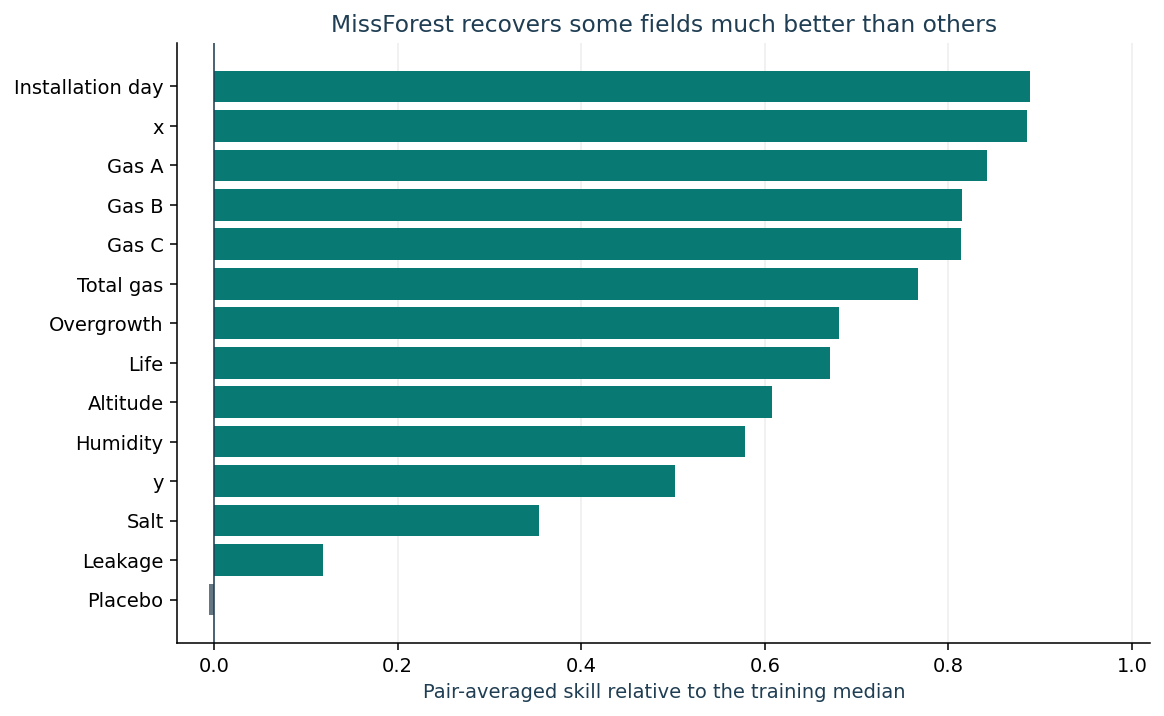

In [4]:
bars = fields.sort_values("Skill")
fig, ax = plt.subplots(figsize=(8.2, 5.0), layout="constrained")
ax.barh(bars.index, bars.Skill, color=[MUTE if f == "Placebo" else TEAL for f in bars.index])
ax.axvline(0, color=NAVY, linewidth=0.8)
ax.set(xlim=(-0.04, 1.02), xlabel="Pair-averaged skill relative to the training median",
       title="MissForest recovers some fields much better than others")
ax.grid(axis="x")
plt.show()

## Interpretation

Gas A, B, and C have skill between 0.81 and 0.84. Life reaches 0.67. The placebo is near zero (−0.005), which is consistent with its role as a random negative control.

Humidity, salt, and overgrowth beat the median, yet fewer than half of the fills meet the loose tolerance on average across pairs. Relative improvement and practical error limits answer different questions. MAE is reported in each field’s own units, so comparisons across fields use skill or within-tolerance share.

“Scored” counts held-out gap occurrences across repetitions. A row may recur in different splits. The pair range describes the observed variation across runs.

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/cells.csv | MissForest anchor, model only, domain features on, group all | 9d8119486d0cbae0 |

[Section 6 of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)